In [190]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

In [191]:

df=pd.DataFrame({
    "study_hours":   [2, 5, 8, 1, 4, 6, 3, 9, 7, 2, 10, 5, 1, 8, 4, 6, 3, 9, 7, 0],
    "sleep_hours":   [6, 7, 6, 5, 8, 7, 6, 7, 5, 8, 6, 6, 7, 8, 5, 8, 7, 6, 7, 6],
    "attendance":    [60, 85, 90, 50, 75, 95, 70, 98, 88, 65, 92, 80, 55, 96, 72, 85, 78, 94, 90, 45],
    "previous_marks":[45, 60, 70, 40, 55, 65, 50, 80, 68, 48, 75, 58, 42, 72, 52, 62, 53, 78, 66, 38],
    "final_marks":   [48, 72, 85, 38, 63, 78, 55, 93, 76, 52, 90, 66, 40, 88, 57, 74, 60, 91, 80, 32],
})
df


,study_hours,sleep_hours,attendance,previous_marks,final_marks
0,2,6,60,45,48
1,5,7,85,60,72
2,8,6,90,70,85
3,1,5,50,40,38
4,4,8,75,55,63
5,6,7,95,65,78
6,3,6,70,50,55
7,9,7,98,80,93
8,7,5,88,68,76
9,2,8,65,48,52


In [192]:
df.isnull().sum()

,0
study_hours,0
sleep_hours,0
attendance,0
previous_marks,0
final_marks,0


In [193]:
X = df[["study_hours", "sleep_hours", "attendance", "previous_marks"]]
y = df["final_marks"]

In [194]:
X_min=X.min()
X_max=X.max()
X_scaled=(X-X_min)/(X_max-X_min+1e-8)

In [195]:
X

,study_hours,sleep_hours,attendance,previous_marks
0,2,6,60,45
1,5,7,85,60
2,8,6,90,70
3,1,5,50,40
4,4,8,75,55
5,6,7,95,65
6,3,6,70,50
7,9,7,98,80
8,7,5,88,68
9,2,8,65,48


In [196]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.5,random_state=42)

In [197]:
model=keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(8,activation="relu"),
    layers.Dense(1) #no act func bcz it is reg problem

])

In [198]:
model.compile(optimizer="adam",loss="mse",metrics=["mae"])
#as it is regression problem so we used MSE as loss
#metrics MAE

In [199]:
history=model.fit(
    X_train.values,y_train.values,
    validation_data=(X_test.values,y_test.values),
    epochs=300,
    batch_size=4,
    verbose=1
)

Epoch 1/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 120ms/step - loss: 2210.0208 - mae: 44.4050 - val_loss: 2160.6013 - val_mae: 45.2303
Epoch 2/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 2140.9946 - mae: 43.6751 - val_loss: 2088.0598 - val_mae: 44.4539
Epoch 3/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 2073.9971 - mae: 42.9479 - val_loss: 2016.4242 - val_mae: 43.6739
Epoch 4/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 2004.5963 - mae: 42.2060 - val_loss: 1947.1949 - val_mae: 42.9066
Epoch 5/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 1933.0349 - mae: 41.4534 - val_loss: 1880.0715 - val_mae: 42.1494
Epoch 6/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 1866.9703 - mae: 40.7140 - val_loss: 1812.0959 - val_mae: 41.3686
Epoch 7/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 1804.7963 - mae: 39.9792 - val_loss: 1742.8590 - val_mae: 40.5581
Epoch 8/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 1735.2122 - mae: 39.1901 - val_loss: 1674.2656 - val_mae: 39.7389
Epoch 9

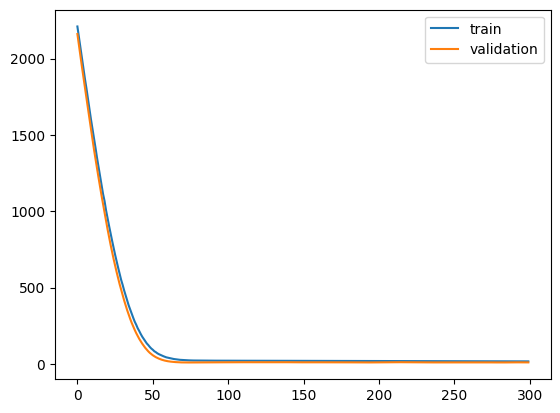

In [200]:
import matplotlib.pyplot as plt
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.legend()
plt.show()

In [201]:
# Evaluate the model on the test data
loss, mae = model.evaluate(X_test.values, y_test.values, verbose=0)

print("Test loss (MSE):", round(loss, 2))
print("Test MAE:", round(mae, 2), "marks")

Test loss (MSE): 10.74
Test MAE: 2.84 marks


In [202]:
# 8. New student predict
new_student = pd.DataFrame([[6, 7, 85, 60]], columns=X.columns)   # study, sleep, attendance, prev marks
pred = model.predict(new_student.values)

print(pred)
print("Predicted marks:", round(float(pred[0][0]), 1))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
[[73.73599]]
Predicted marks: 73.7
